<a href="https://colab.research.google.com/github/sabrinabdi0/Intro-to-back-end/blob/main/knn_vs_logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# KNN vs Logistic Regression: Breast Cancer Diagnosis

**Author:** Sabrin

**Dataset:** Breast Cancer Wisconsin (Diagnostic), UCI Machine Learning Repository
**Link:** https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic

**Goal:** Predict if a tumor is **malignant (M)** or **benign (B)** using 30 measurements, and compare two models: K-Nearest Neighbors (classification) and Logistic Regression.

## Setup
I first installed the required tool that downloads the dataset and loading the required libraries.

In [1]:
# Installing the helper that downloads UCI datasets
!pip install ucimlrepo -q

In [2]:
# Libraries
import numpy as np                      # numbers and maths
import pandas as pd                     # tables (DataFrames)
import matplotlib.pyplot as plt         # charts
import seaborn as sns                   # nicer charts

from ucimlrepo import fetch_ucirepo     # downloads the dataset

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)

sns.set_style("whitegrid")              # clean chart style

## Step A: Data Preparation

### A1. Load the data
`id=17` is the number of this dataset on UCI.

In [3]:
# Downloaded the dataset from UCI
data = fetch_ucirepo(id=17)

X = data.data.features      # the 30 measurements that are used to make predictions
y = data.data.targets       # the answer we want to predict (M or B)

# Joining them into one table so we can look at everything together
df = pd.concat([X, y], axis=1)
df.head()                   # first 5 rows

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,M
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,M
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,M
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,M
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,M


In [ ]:
# Showing each column's name, type, and how many values are not missing
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   radius1             569 non-null    float64
 1   texture1            569 non-null    float64
 2   perimeter1          569 non-null    float64
 3   area1               569 non-null    float64
 4   smoothness1         569 non-null    float64
 5   compactness1        569 non-null    float64
 6   concavity1          569 non-null    float64
 7   concave_points1     569 non-null    float64
 8   symmetry1           569 non-null    float64
 9   fractal_dimension1  569 non-null    float64
 10  radius2             569 non-null    float64
 11  texture2            569 non-null    float64
 12  perimeter2          569 non-null    float64
 13  area2               569 non-null    float64
 14  smoothness2         569 non-null    float64
 15  compactness2        569 non-null    float64
 16  concavit

In [4]:
# checks
print("Rows, columns:", df.shape)
print("Total missing values:", df.isnull().sum().sum())
print()
print("How many of each diagnosis?")
print(y.iloc[:, 0].value_counts())

Rows, columns: (569, 31)
Total missing values: 0

How many of each diagnosis?
Diagnosis
B    357
M    212
Name: count, dtype: int64


### A2. Clean and encode
- **Missing values:** the check above should show 0, so nothing to fix.
- **Encoding:** computers need numbers, not letters. We change the diagnosis to **M = 1** and **B = 0**.

In [5]:
# Turn the letters into numbers: M (malignant) = 1, B (benign) = 0
y = data.data.targets.iloc[:, 0].map({"M": 1, "B": 0})

# Drop any rows with missing values (safe to run even when there are none)
mask = X.notna().all(axis=1) & y.notna()
X, y = X[mask], y[mask]

print(y.value_counts())

Diagnosis
0    357
1    212
Name: count, dtype: int64


### A3. Split into training and testing sets
- **Training set (80%):** the models learn from this.
- **Testing set (20%):** kept hidden, used only to check how well the models learned.
- `random_state=42` makes the split the same every time.
- `stratify=y` keeps the same mix of M and B in both sets.

We split **before** scaling. If we scaled first, information from the test set would leak into training. That would make the results look better than they really are.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows: ", X_test.shape[0])

Training rows: 455
Testing rows:  114


### A4. Scale the features
The 30 measurements have very different sizes (for example, area is in the hundreds, smoothness is below 1).
KNN measures distances, so big numbers would unfairly dominate.

`StandardScaler` puts every feature on the same scale (average 0, spread 1).
- `fit_transform` on training data: learns the scale, then applies it.
- `transform` on testing data: applies the **same** scale.

In [7]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   # learn from training data only
X_test_scaled  = scaler.transform(X_test)        # reuse the same scale

# Check: training means should be about 0 and spreads about 1
print("Mean of first 3 features:", X_train_scaled.mean(axis=0)[:3].round(3))
print("Std of first 3 features: ", X_train_scaled.std(axis=0)[:3].round(3))

Mean of first 3 features: [-0.  0.  0.]
Std of first 3 features:  [1. 1. 1.]


## Step B: K-Nearest Neighbors (KNN)

**How KNN works (simple version):** to classify a new tumor, it finds the **k** most similar tumors in the training data and takes a vote.

### B1. Choose the best k
We try odd values of k from 1 to 25. For each one, we test it 5 times on different slices of the **training** data (cross-validation). Then we pick the best k.

Best k: 3


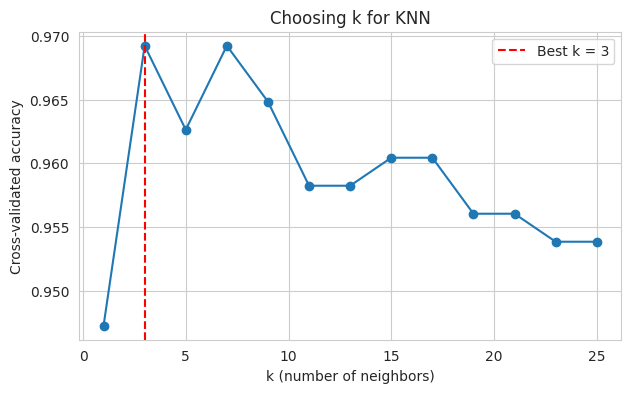

In [8]:
k_values = list(range(1, 26, 2))     # 1, 3, 5, ..., 25
cv_scores = []

for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    score = cross_val_score(knn_temp, X_train_scaled, y_train, cv=5, scoring="accuracy").mean()
    cv_scores.append(score)

best_k = k_values[int(np.argmax(cv_scores))]
print("Best k:", best_k)

# Chart: accuracy for each k
plt.figure(figsize=(7, 4))
plt.plot(k_values, cv_scores, marker="o")
plt.axvline(best_k, color="red", linestyle="--", label=f"Best k = {best_k}")
plt.xlabel("k (number of neighbors)")
plt.ylabel("Cross-validated accuracy")
plt.title("Choosing k for KNN")
plt.legend()
plt.show()

### B2. Train KNN and test it

KNN (k = 3)
Accuracy: 0.9386

Confusion Matrix:
[[71  1]
 [ 6 36]]

Classification Report:
               precision    recall  f1-score   support

   Benign (0)       0.92      0.99      0.95        72
Malignant (1)       0.97      0.86      0.91        42

     accuracy                           0.94       114
    macro avg       0.95      0.92      0.93       114
 weighted avg       0.94      0.94      0.94       114



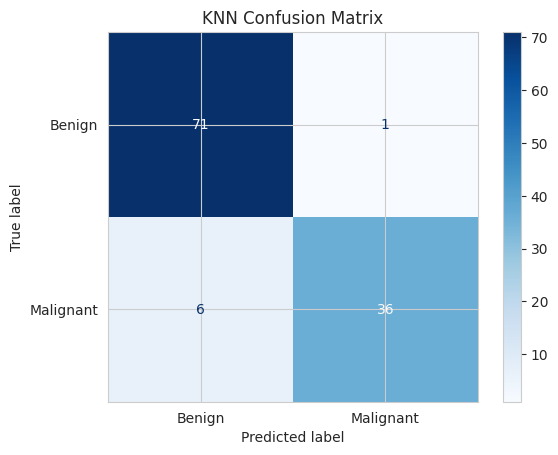

In [9]:
# Train
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_scaled, y_train)

# Predict on the hidden test set
knn_pred  = knn.predict(X_test_scaled)
knn_proba = knn.predict_proba(X_test_scaled)[:, 1]   # probability of malignant (used for ROC)

# Results
print(f"KNN (k = {best_k})")
print("Accuracy:", round(accuracy_score(y_test, knn_pred), 4))
print()
print("Confusion Matrix:")
print(confusion_matrix(y_test, knn_pred))
print()
print("Classification Report:")
print(classification_report(y_test, knn_pred, target_names=["Benign (0)", "Malignant (1)"]))

ConfusionMatrixDisplay.from_predictions(
    y_test, knn_pred, display_labels=["Benign", "Malignant"], cmap="Blues"
)
plt.title("KNN Confusion Matrix")
plt.show()

**How to read the confusion matrix:**
- Top-left: benign correctly called benign.
- Bottom-right: malignant correctly called malignant.
- Top-right: benign wrongly called malignant (false alarm).
- Bottom-left: malignant wrongly called benign (**the most serious mistake**).

## Step C: Logistic Regression

**How it works (simple version):** it gives each feature a weight (coefficient), adds them up, and turns the total into a probability between 0 and 1. Above 0.5 means malignant.

We use **Logistic** Regression (not Linear) because our target is a yes/no answer.

Logistic Regression
Accuracy: 0.9649
ROC-AUC:  0.996

Confusion Matrix:
[[71  1]
 [ 3 39]]

Classification Report:
               precision    recall  f1-score   support

   Benign (0)       0.96      0.99      0.97        72
Malignant (1)       0.97      0.93      0.95        42

     accuracy                           0.96       114
    macro avg       0.97      0.96      0.96       114
 weighted avg       0.97      0.96      0.96       114



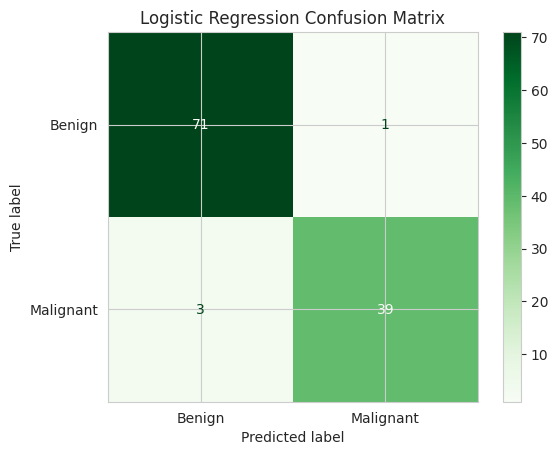

In [10]:
# Train
logreg = LogisticRegression(max_iter=1000, random_state=42)
logreg.fit(X_train_scaled, y_train)

# Predict on the hidden test set
log_pred  = logreg.predict(X_test_scaled)
log_proba = logreg.predict_proba(X_test_scaled)[:, 1]

# Results
print("Logistic Regression")
print("Accuracy:", round(accuracy_score(y_test, log_pred), 4))
print("ROC-AUC: ", round(roc_auc_score(y_test, log_proba), 4))
print()
print("Confusion Matrix:")
print(confusion_matrix(y_test, log_pred))
print()
print("Classification Report:")
print(classification_report(y_test, log_pred, target_names=["Benign (0)", "Malignant (1)"]))

ConfusionMatrixDisplay.from_predictions(
    y_test, log_pred, display_labels=["Benign", "Malignant"], cmap="Greens"
)
plt.title("Logistic Regression Confusion Matrix")
plt.show()

### Coefficients
A **positive** coefficient pushes the prediction toward malignant. A **negative** one pushes toward benign.
Bigger size (ignoring the sign) means a stronger effect. Here are the 10 strongest.

In [12]:
coef_table = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logreg.coef_[0]
})
coef_table["Strength"] = coef_table["Coefficient"].abs()
coef_table = coef_table.sort_values("Strength", ascending=False).drop(columns="Strength")

print("Intercept:", round(logreg.intercept_[0], 4))
coef_table.head(10).reset_index(drop=True)

Intercept: -0.243


,Feature,Coefficient
0,texture3,1.434093
1,radius2,1.233325
2,symmetry3,1.061264
3,concave_points1,0.952813
4,concavity3,0.911406
5,area2,0.909029
6,compactness2,-0.906925
7,area3,0.900477
8,radius3,0.896968
9,concavity1,0.782298


## Step D: Model Comparison
Both models used the **same** training and testing split, so the comparison is fair.

### D1. Side-by-side table

In [14]:
def summarize(name, y_true, y_pred, y_proba):
    return {
        "Model": name,
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall":    recall_score(y_true, y_pred),
        "F1-score":  f1_score(y_true, y_pred),
        "ROC-AUC":   roc_auc_score(y_true, y_proba),
    }

comparison = pd.DataFrame([
    summarize(f"KNN (k={best_k})", y_test, knn_pred, knn_proba),
    summarize("Logistic Regression", y_test, log_pred, log_proba),
]).set_index("Model").round(4)

comparison

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
KNN (k=3),0.9386,0.973,0.8571,0.9114,0.9825
Logistic Regression,0.9649,0.975,0.9286,0.9512,0.9960


**What the columns mean:**
- **Accuracy:** share of all predictions that were right.
- **Precision:** when it says malignant, how often is it right?
- **Recall:** of all truly malignant tumors, how many did it catch? (Very important here.)
- **F1-score:** a balance of precision and recall.
- **ROC-AUC:** how well the model separates the two groups (1.0 is perfect, 0.5 is guessing).

### D2. Charts

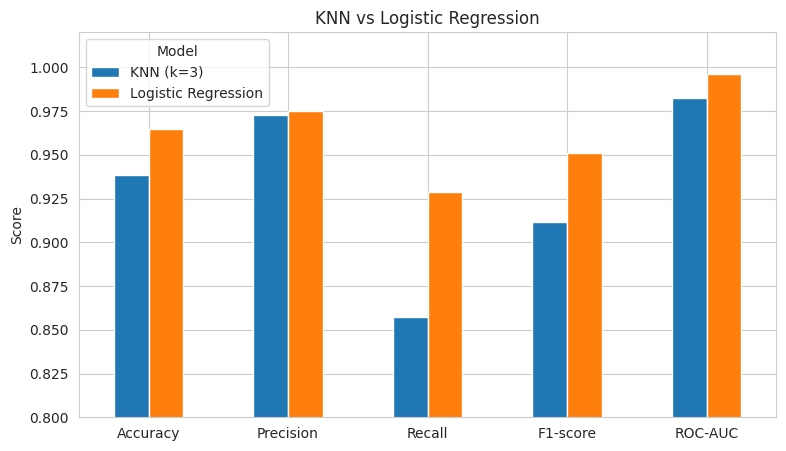

In [ ]:
# Chart 1: bar chart comparing the metrics
comparison.T.plot(kind="bar", figsize=(9, 5), rot=0)
plt.title("KNN vs Logistic Regression")
plt.ylabel("Score")
plt.ylim(0.8, 1.02)          # zoomed in so small differences are visible
plt.legend(title="Model")
plt.show()

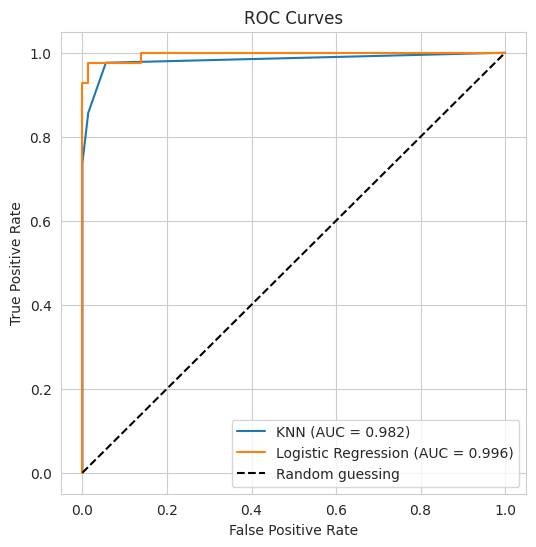

In [ ]:
# Chart 2: ROC curves (closer to the top-left corner = better)
fpr_knn, tpr_knn, _ = roc_curve(y_test, knn_proba)
fpr_log, tpr_log, _ = roc_curve(y_test, log_proba)

plt.figure(figsize=(6, 6))
plt.plot(fpr_knn, tpr_knn, label=f"KNN (AUC = {roc_auc_score(y_test, knn_proba):.3f})")
plt.plot(fpr_log, tpr_log, label=f"Logistic Regression (AUC = {roc_auc_score(y_test, log_proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guessing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend(loc="lower right")
plt.show()

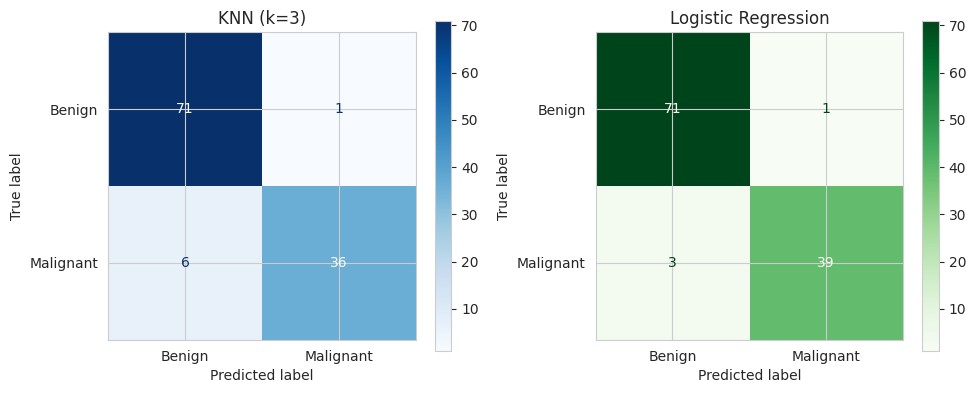

In [ ]:
# Chart 3: both confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, knn_pred, display_labels=["Benign", "Malignant"], cmap="Blues", ax=axes[0])
axes[0].set_title(f"KNN (k={best_k})")

ConfusionMatrixDisplay.from_predictions(
    y_test, log_pred, display_labels=["Benign", "Malignant"], cmap="Greens", ax=axes[1])
axes[1].set_title("Logistic Regression")

plt.tight_layout()
plt.show()

## Conclusion
Results from this run (`random_state=42`, 455 training rows, 114 test rows):

1. **Accuracy:** Logistic Regression scored **0.9649** and KNN (k = 3) scored **0.9386**. That is about 0.026 higher, or 4 mistakes instead of 7.
2. **Recall (malignant):** Logistic Regression **0.9286** vs KNN **0.8571**. Logistic Regression missed 3 malignant tumors and KNN missed 6. Missing a malignant tumor is the most serious kind of mistake in cancer detection, because the patient may not get treatment.
3. **ROC-AUC:** Logistic Regression **0.996** vs KNN **0.982**. Both are very high.
4. **Why Logistic Regression may have done better:**
   - After scaling, the two classes look separable by a fairly straight boundary, which is what Logistic Regression fits.
   - KNN with k = 3 lets only three neighbors vote, so a few unusual tumors can flip a prediction.
   - KNN treats all 30 features equally, while Logistic Regression can give unhelpful features small weights.
5. **Recommendation:** Logistic Regression. It has higher recall and AUC, equal precision (0.975 vs 0.973), and its coefficients can be explained.
6. **Limitations:** this is one dataset with 569 rows and one train/test split. The gap is only 3 tumors, so a different split could change it. Cross-validating both models on all the data would give a firmer answer.

**Important:** these results are for a class project and are not medical advice.